# EDA для e-commerce за октябрь

# Первичный осмотр

Будем использовать библиотеку `duckdb` для работы с большим количеством данных, а `pandas` уже для обработки мелких групп

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb 

sns.set_theme(style='darkgrid')

In [2]:
path = 'D:/kaggle_data/2019-Oct.csv'

con = duckdb.connect('ecommerce.duckdb')

con.execute(f"""
            CREATE OR REPLACE TABLE events AS 
            SELECT * FROM read_csv_auto('{path}')
""")

con.close()

In [49]:
con = duckdb.connect('ecommerce.duckdb')

con.sql("""
    SELECT *
    FROM events
    LIMIT 5
    """
).show()

┌─────────────────────┬────────────┬────────────┬─────────────────────┬─────────────────────────────────────┬──────────┬─────────┬───────────┬──────────────────────────────────────┐
│     event_time      │ event_type │ product_id │     category_id     │            category_code            │  brand   │  price  │  user_id  │             user_session             │
│      timestamp      │  varchar   │   int64    │        int64        │               varchar               │ varchar  │ double  │   int64   │               varchar                │
├─────────────────────┼────────────┼────────────┼─────────────────────┼─────────────────────────────────────┼──────────┼─────────┼───────────┼──────────────────────────────────────┤
│ 2019-10-01 00:00:00 │ view       │   44600062 │ 2103807459595387724 │ NULL                                │ shiseido │   35.79 │ 541312140 │ 72d76fde-8bb3-4e00-8c23-a032dfed738c │
│ 2019-10-01 00:00:00 │ view       │    3900821 │ 2053013552326770905 │ appliances.environ

## Общие сведения

In [4]:
con.sql('SUMMARIZE events').df()

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,event_time,TIMESTAMP,2019-10-01 00:00:00,2019-10-31 23:59:59,2675444,2019-10-16 13:03:06.605022,NaN,2019-10-09 07:24:15.233527,2019-10-16 12:02:41.409613,2019-10-23 20:13:43.579452,42448764,0.00
1,event_type,VARCHAR,cart,view,3,NaN,NaN,NaN,NaN,NaN,42448764,0.00
2,product_id,BIGINT,1000978,60500010,177851,10549932.375842676,11881906.970608281,1005154,4969616,16110876,42448764,0.00
3,category_id,BIGINT,2053013552226107603,2175419595093967522,872,2.0574042379407946e+18,1.8439264661404212e+16,2053013555458806272,2053013555631883264,2053013563359587072,42448764,0.00
4,category_code,VARCHAR,accessories.bag,stationery.cartrige,121,NaN,NaN,NaN,NaN,NaN,42448764,31.84
5,brand,VARCHAR,a-case,zyxel,3516,NaN,NaN,NaN,NaN,NaN,42448764,14.40
6,price,DOUBLE,0.0,2574.07,78322,290.32366068492445,358.26915533940763,66.02137223156632,163.38046253155494,357.56025107089306,42448764,0.00
7,user_id,BIGINT,33869381,566280860,3455844,533537147.50816846,18523738.174653154,515916200,529570215,551508385,42448764,0.00
8,user_session,VARCHAR,00000042-3e3f-42f9-810d-f3d264139c50,fffffc65-7ce9-435c-8b72-1d9f7062fe77,11390309,NaN,NaN,NaN,NaN,NaN,42448764,0.00


In [5]:
df_size = con.sql("""
           SELECT COUNT(*) AS nRow
           FROM events
           """).df()
nCol = con.sql("""
               SELECT *
               FROM events
               LIMIT 1
               """).df().shape[1]
df_size['nCol'] = nCol
df_size

#nRow, nCol = df.shape
#print(f'There are {nCol} columns and {nRow} rows')

,nRow,nCol
0,42448764,9


### Посчитаем отдельно ключевые параметры

Посчитаем пустые значения:

In [6]:
nulls = con.sql("""
                   SELECT count(*) FILTER(WHERE event_time IS NULL) as event_time, 
                    count(*) FILTER(WHERE event_type IS NULL) as event_type, 
                    count(*) FILTER(WHERE product_id IS NULL) as product_id, 
                    count(*) FILTER(WHERE category_id IS NULL) as category_id, 
                    count(*) FILTER(WHERE category_code IS NULL) as category_code, 
                    count(*) FILTER(WHERE brand IS NULL) as brand, 
                    count(*) FILTER(WHERE price IS NULL) as price, 
                    count(*) FILTER(WHERE user_id IS NULL) as user_id, 
                    count(*) FILTER(WHERE user_session IS NULL) as user_session, 
                   
                   FROM events
""").df()
# print('Quantity of not a number elements: \n',df.isna().sum())
# print("\nMean value of not a number in our columns: \n", df.isna().mean().round(2)*100)
# 
# print("\nHow many duplicates in our data frame->", df.duplicated().sum())

In [7]:
nulls.T

,0
event_time,0
event_type,0
product_id,0
category_id,0
category_code,13515609
brand,6113008
price,0
user_id,0
user_session,2


Общая прибыль:

In [8]:
con.sql("""
        SELECT ROUND(SUM(price), 2) AS total_price
        FROM events 
        WHERE event_type = 'purchase'       
""").show()

┌──────────────┐
│ total_price  │
│    double    │
├──────────────┤
│ 229957502.27 │
└──────────────┘



Проверим есть ли какие-то аномалии в price.

- посмотрим сколько товаров имеют price = 0, и для каких event_type они соответствуют 
- сделаем SQL-запрос для нахождения Q1, median, Q3, max, min
- сделаем boxplot для выборки из 200000 строк

In [9]:
con.sql("""
        SELECT COUNT(price) FILTER(WHERE event_type='view') as cnt_free_view,
        COUNT(price) FILTER(WHERE event_type='cart') as cnt_free_cart,
        COUNT(price) FILTER(WHERE event_type='purchase') as cnt_free_purchase
        FROM events       
        WHERE price=0        
""").show()

con.sql("""
        SELECT MIN(price) AS min,
        QUANTILE_CONT(price, 0.25) AS Q1,
        QUANTILE_CONT(price, 0.5) AS median,
        QUANTILE_CONT(PRICE, 0.75) AS Q3,
        MAX(price) AS max
        FROM events      
""").show()

┌───────────────┬───────────────┬───────────────────┐
│ cnt_free_view │ cnt_free_cart │ cnt_free_purchase │
│     int64     │     int64     │       int64       │
├───────────────┼───────────────┼───────────────────┤
│         68523 │           150 │                 0 │
└───────────────┴───────────────┴───────────────────┘

┌────────┬────────┬────────┬────────┬─────────┐
│  min   │   Q1   │ median │   Q3   │   max   │
│ double │ double │ double │ double │ double  │
├────────┼────────┼────────┼────────┼─────────┤
│    0.0 │  65.98 │ 162.93 │ 358.57 │ 2574.07 │
└────────┴────────┴────────┴────────┴─────────┘



Мы получили то, что price = 0 преимущественно у тех товаров, которые только посмотрели. Почему бы их сразу не положить в корзину? И у нас даже нет ни одного человека, кто купил бы по такому price. Возможно это просто баг.

Попробуем посчитать Q1, median, Q3, max, min для price, но с условием, что он не равен нулю:

In [10]:
con.sql("""
        SELECT MIN(price) AS min,
        QUANTILE_CONT(price, 0.25) AS Q1,
        QUANTILE_CONT(price, 0.5) AS median,
        QUANTILE_CONT(PRICE, 0.75) AS Q3,
        MAX(price) AS max
        FROM events      
        WHERE PRICE != 0
""").show()

┌────────┬────────┬────────┬────────┬─────────┐
│  min   │   Q1   │ median │   Q3   │   max   │
│ double │ double │ double │ double │ double  │
├────────┼────────┼────────┼────────┼─────────┤
│   0.77 │  66.66 │ 163.97 │ 358.57 │ 2574.07 │
└────────┴────────┴────────┴────────┴─────────┘



Впринципе, квантили и значение минимума не сильно поменялось. Построит boxplot по неделям для выборки из 200000 заказов, которые имеет статус 'purchase'

<Axes: xlabel='week', ylabel='price'>

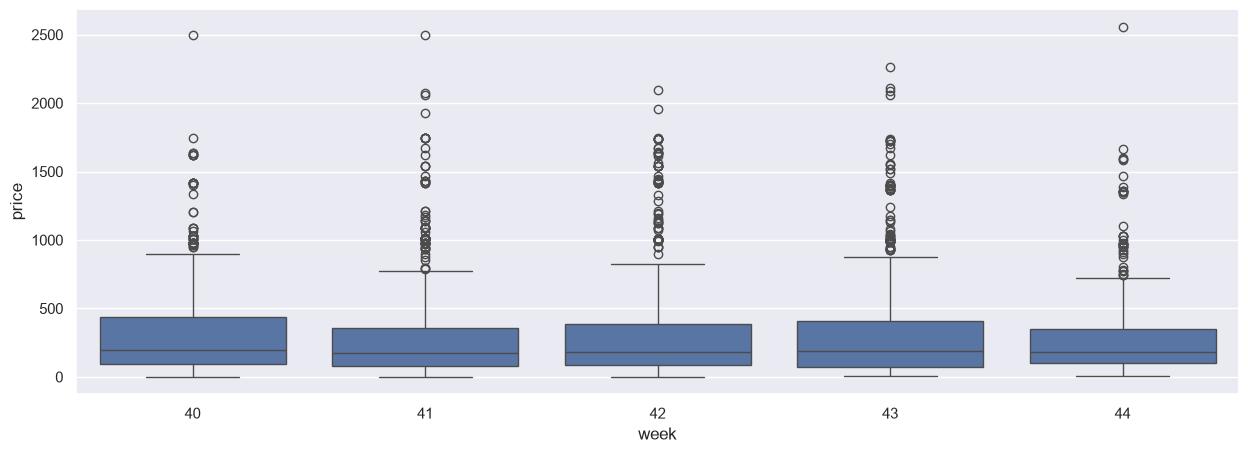

In [11]:
price_df = con.sql("""
        SELECT price, EXTRACT(WEEK FROM event_time) as week
        FROM events
        WHERE event_type='purchase' AND price != 0
        USING SAMPLE 200000 ROWS
                
""").df()

plt.figure(figsize=(15,5))
sns.boxplot(data = price_df, x='week', y='price') 

Видно, что основная стоимость заказов, которые имеют больший спрос распологаеются на отрезке от 66.66 до 358.57.

Сделаем другой график, который поможет нам лучше понять поведение медианы и межквартального размаха (IQR):

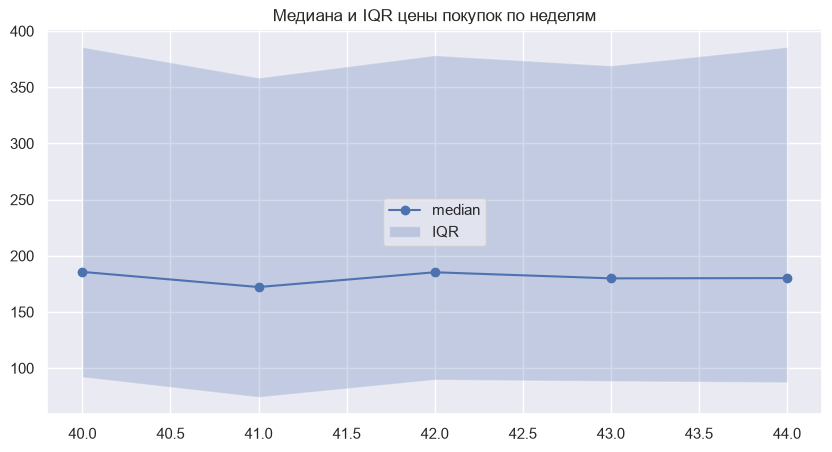

In [12]:
# Считаем медиану и квантили в SQL — точные числа без семпла
weekly = con.sql("""
    SELECT
        EXTRACT(WEEK FROM event_time) AS week,
        QUANTILE_CONT(price, 0.25) AS q1,
        QUANTILE_CONT(price, 0.5)  AS median,
        QUANTILE_CONT(price, 0.75) AS q3,
        COUNT(*)                   AS n_purchases
    FROM events
    WHERE event_type = 'purchase'
    GROUP BY 1
    ORDER BY 1
""").df()

plt.figure(figsize=(10, 5))
plt.plot(weekly['week'], weekly['median'], marker='o', label='median')
plt.fill_between(weekly['week'], weekly['q1'], weekly['q3'], alpha=0.25, label='IQR')
plt.legend()
plt.title('Медиана и IQR цены покупок по неделям')
plt.show()

Посмотрим какие вообще значения принимают столбцы, где хранятся категории товаров:

In [13]:
con.sql("""
                  SELECT 'event_type' AS col, COUNT(DISTINCT event_type) AS nunique, list(DISTINCT event_type)[:5] AS sample
                  FROM events
                  UNION ALL
                  SELECT 'category_code', COUNT(DISTINCT category_code), list(DISTINCT category_code)[:5]
                  FROM events
                  UNION ALL
                  SELECT 'brand', COUNT(DISTINCT brand), list(DISTINCT brand)[:5]
                  FROM events
                  """).show()

┌───────────────┬─────────┬────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
│      col      │ nunique │                                                               sample                                                               │
│    varchar    │  int64  │                                                             varchar[]                                                              │
├───────────────┼─────────┼────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ event_type    │       3 │ [purchase, cart, view]                                                                                                             │
│ category_code │     126 │ [furniture.living_room.sofa, computers.notebook, electronics.video.tv, appliances.environment.air_heater, construction.tools.pump] │
│ brand         │    3445 │ [lenov

Бренды и их наиболее часто покупаемые категории:

In [14]:
con.sql('''
        WITH cnt_cat AS(
            SELECT brand, category_code, COUNT(*) as cnt
            FROM events
            WHERE event_type='purchase' AND category_code IS NOT NULL AND brand IS NOT NULL
            GROUP BY brand, category_code
            ORDER BY brand
        ),
        ranked_cat AS(
            SELECT brand, category_code, 
            ROW_NUMBER() OVER(PARTITION BY brand
                              ORDER BY cnt DESC) as rn, cnt
            FROM cnt_cat
            ORDER BY brand
        )
        SELECT brand, category_code, cnt AS count
        FROM ranked_cat
        WHERE rn=1
        ORDER BY count DESC
        LIMIT 10
        
''').show()

┌─────────┬───────────────────────────┬────────┐
│  brand  │       category_code       │ count  │
│ varchar │          varchar          │ int64  │
├─────────┼───────────────────────────┼────────┤
│ samsung │ electronics.smartphone    │ 143123 │
│ apple   │ electronics.smartphone    │ 115345 │
│ xiaomi  │ electronics.smartphone    │  38776 │
│ huawei  │ electronics.smartphone    │  21882 │
│ oppo    │ electronics.smartphone    │  10891 │
│ acer    │ computers.notebook        │   6018 │
│ lenovo  │ computers.notebook        │   3990 │
│ artel   │ electronics.video.tv      │   3053 │
│ lg      │ appliances.kitchen.washer │   2903 │
│ indesit │ appliances.kitchen.washer │   2660 │
└─────────┴───────────────────────────┴────────┘
  10 rows                            3 columns



Количество продаж по дням:

<Axes: xlabel='day', ylabel='cnt'>

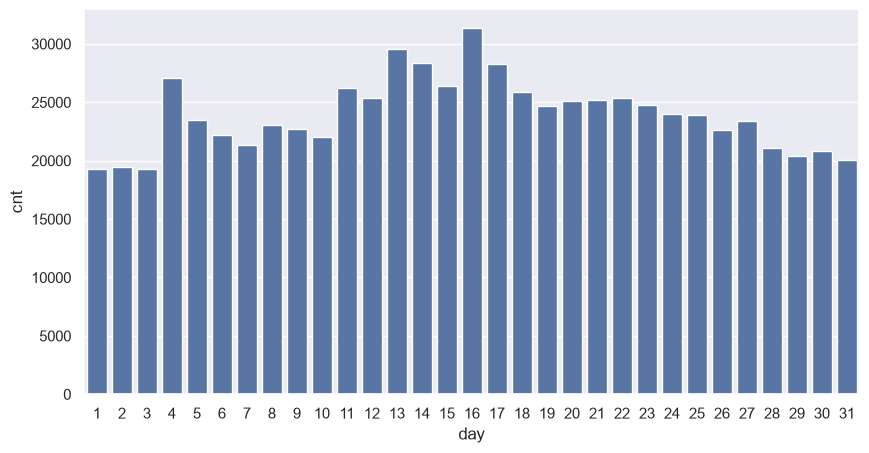

In [15]:
cnt_sale_per_day = con.sql('''
        SELECT EXTRACT(day FROM event_time) as day, COUNT(*) as cnt
        FROM events
        WHERE event_type='purchase'
        GROUP BY EXTRACT(day FROM event_time)
''').df()
plt.figure(figsize=(10,5))
sns.barplot(cnt_sale_per_day, x='day', y='cnt')

Выручка по дням:

<Axes: xlabel='day', ylabel='price'>

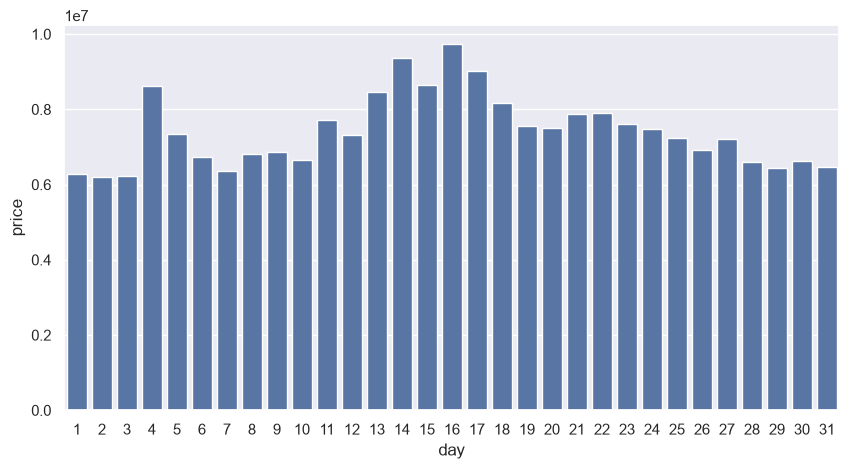

In [16]:
price_sale_per_day = con.sql('''
        SELECT EXTRACT(day FROM event_time) as day, SUM(price) as price
        FROM events
        WHERE event_type='purchase'
        GROUP BY EXTRACT(day FROM event_time)
''').df()

plt.figure(figsize=(10,5))
sns.barplot(price_sale_per_day, x='day', y='price')

Посмотрим самое ранние и самое позднее время транзакций:

In [17]:
con.sql("""
        SELECT MAX(event_time) AS last_transaction, MIN(event_time) AS early_transaction
        FROM events
        """).show()

┌─────────────────────┬─────────────────────┐
│  last_transaction   │  early_transaction  │
│      timestamp      │      timestamp      │
├─────────────────────┼─────────────────────┤
│ 2019-10-31 23:59:59 │ 2019-10-01 00:00:00 │
└─────────────────────┴─────────────────────┘



Количество уникальных пользователей:

In [71]:
unique_user = con.sql('''
                        SELECT COUNT(DISTINCT user_id) AS cnt_of_user
                        FROM events
                        ''').df()
unique_user

,cnt_of_user
0,3022290


Количество уникальных сессий:

In [19]:
unique_session = con.sql('''
                        SELECT COUNT(DISTINCT user_session) AS cnt_of_session
                        FROM events
                        ''').df()
unique_session

,cnt_of_session
0,9244421


Сколько сессий среднем приходится на одного пользователя:

In [20]:
con.sql("""
        WITH user_ses_cnt AS(
                SELECT COUNT(DISTINCT user_session) as cnt
                FROM events
                GROUP BY user_id
        )
        SELECT ROUND(AVG(cnt), 2) AS avg_session_per_user
        FROM user_ses_cnt
        """).show()

┌──────────────────────┐
│ avg_session_per_user │
│        double        │
├──────────────────────┤
│                 3.06 │
└──────────────────────┘



## Статистические сведения

### Распределение этапов

Найдем отношение $\frac{\text{кол-во прошедших этап (или находятся на нём)}}{\text{все люди}}$ для каждого этапа 

  event_type       cnt    pct
0       view  40779399  96.07
1       cart    926516   2.18
2   purchase    742849   1.75


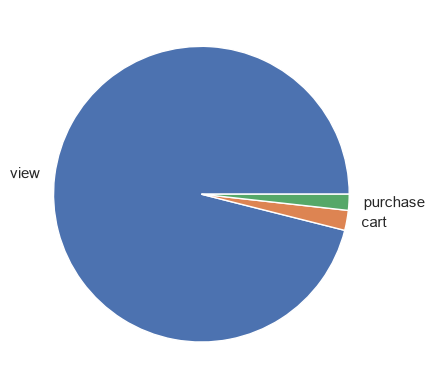

In [21]:
event_cnt = con.sql("""
        SELECT event_type, 
            COUNT(*) as cnt, 
            ROUND(COUNT(*) / SUM(COUNT(*)) OVER() * 100, 2) AS pct
        FROM events
        GROUP BY event_type
        """).df()
print(event_cnt)
plt.pie(event_cnt['cnt'], labels=event_cnt['event_type'])
plt.show()

### Сделаем строгую воронку этапов _по сессиям_

In [22]:
session_funnel = con.sql("""
        WITH views AS(
            SELECT user_session, MIN(event_time) AS t_view
            FROM events 
            WHERE event_type='view'
            GROUP BY user_session
        ),
        carts AS(
            SELECT e.user_session, MIN(e.event_time) AS t_cart
            FROM events e JOIN views v USING(user_session)
            WHERE e.event_type='cart' AND e.event_time >= v.t_view
            GROUP BY e.user_session
        ),
        purchase AS(
            SELECT e.user_session, MIN(e.event_time) AS t_purchase
            FROM events e JOIN carts c USING(user_session)
            WHERE e.event_type='purchase' AND e.event_time >= c.t_cart
            GROUP BY e.user_session
        )
        
        SELECT (SELECT COUNT(*) FROM views) as viewed,
               (SELECT COUNT(*) FROM carts) as carted,
               (SELECT COUNT(*) FROM purchase) as purchased
        """).df()

    viewed  carted  purchased
0  9242653  571061     289507
   viewed  carted  purchased
0   100.0    6.18       3.13


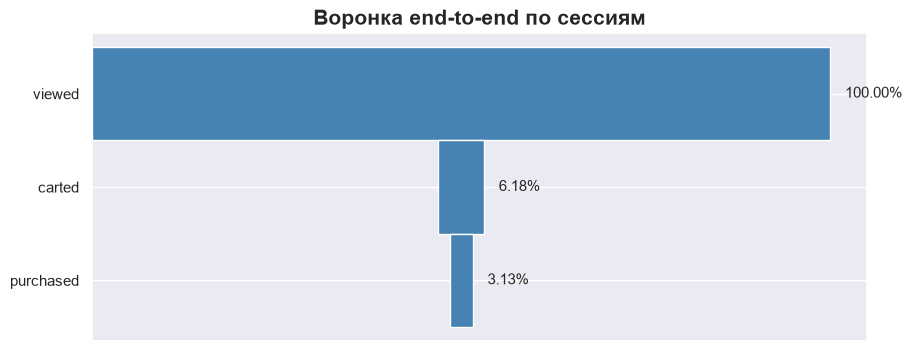

In [ ]:
print(session_funnel)

pct_session_funnel = session_funnel.copy()

pct_session_funnel['viewed']=(session_funnel['viewed']/session_funnel['viewed']*100).round(2)
pct_session_funnel['carted']=(session_funnel['carted']/session_funnel['viewed']*100).round(2)
pct_session_funnel['purchased']=(session_funnel['purchased']/session_funnel['viewed']*100).round(2)

print(pct_session_funnel)


stages = ['viewed', 'carted', 'purchased']

plot_df = pct_session_funnel[stages].T
plot_df.columns = ['pct']
plot_df = plot_df.reindex(stages)  
values = plot_df['pct'].values
lefts = (values.max() - values) / 2         
y = np.arange(len(values))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(y, values, left=lefts, color='steelblue', height=1)

ax.set_yticks(y, plot_df.index)
ax.invert_yaxis()
ax.set_xticks([])                             

for i, (v, l) in enumerate(zip(values, lefts)):
    ax.text(l + v + 2, i, f'{v:.2f}%', va='center', fontsize=11)

ax.set_title('Воронка end-to-end по сессиям', fontsize=15, fontweight='bold')
fig.savefig('img/session_funnel.png')
plt.show()

__Конверсии__ $viewed\rightarrow cart$, $cart\rightarrow purchased$ 

In [24]:
CR_session = pd.DataFrame()

CR_session['v_to_c'] = (session_funnel['carted']/session_funnel['viewed']*100).round(2) 
CR_session['c_to_p'] = (session_funnel['purchased']/session_funnel['carted']*100).round(2) 

CR_session

,v_to_c,c_to_p
0,6.18,50.7


### Сделаем воронку, но теперь не по сессиям, а _по пользователям_

In [25]:
users_funnel = con.sql('''
    WITH viewed AS(
        SELECT user_id, MIN(event_time) as t_v
        FROM events
        WHERE event_type = 'view'
        GROUP BY user_id
    ),
    carted AS(
        SELECT e.user_id, MIN(e.event_time) as t_c
        FROM events e JOIN viewed v ON e.user_id = v.user_id AND e.event_time >= t_v
        WHERE event_type = 'cart' 
        GROUP BY e.user_id
    ),
    purchased AS(
        SELECT e.user_id, MIN(e.event_time) as t_p
        FROM events e JOIN carted c ON e.user_id = c.user_id AND e.event_time >= t_c
        WHERE event_type = 'purchase'
        GROUP BY e.user_id 
    )        
    SELECT (SELECT COUNT(*) FROM viewed) AS viewed,
           (SELECT COUNT(*) FROM carted) AS carted,
           (SELECT COUNT(*) FROM purchased) AS purchased
''').df()

    viewed  carted  purchased
0  3022130  336812     196505
   viewed  carted  purchased
0   100.0   11.14        6.5


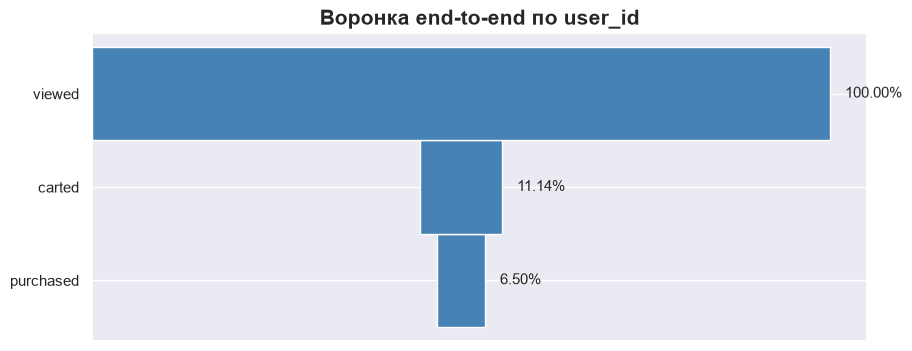

In [ ]:
print(users_funnel)

pct_users_funnel = users_funnel.copy()

pct_users_funnel['viewed'] = (users_funnel['viewed']/users_funnel['viewed']*100).round(2)
pct_users_funnel['carted'] = (users_funnel['carted']/users_funnel['viewed']*100).round(2)
pct_users_funnel['purchased'] = (users_funnel['purchased']/users_funnel['viewed']*100).round(2)

print(pct_users_funnel)

stages = ['purchased', 'carted', 'viewed']
plot_df = pct_users_funnel[stages].T
plot_df.columns = ['pct']
plot_df = plot_df.reindex(stages)  
values = plot_df['pct'].values
lefts = (values.max() - values) / 2         
y = np.arange(len(values))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(y, values, left=lefts, color='steelblue', height=1)

ax.set_yticks(y, plot_df.index)
ax.set_xticks([])                             

for i, (v, l) in enumerate(zip(values, lefts)):
    ax.text(l + v + 2, i, f'{v:.2f}%', va='center', fontsize=11)

ax.set_title('Воронка end-to-end по user_id', fontsize=15, fontweight='bold')
fig.savefig('img/users_funnel.png')
plt.show()

__Конверсии__ $viewed\rightarrow cart$, $cart\rightarrow purchased$ 

In [27]:
CR_users = pd.DataFrame()

CR_users['v_to_c'] = (users_funnel['carted']/users_funnel['viewed']*100).round(2) 
CR_users['c_to_p'] = (users_funnel['purchased']/users_funnel['carted']*100).round(2) 

CR_users

,v_to_c,c_to_p
0,11.14,58.34


Явно сравним конверсии по `session_id` и по `user_id`

In [28]:
users_value = users_funnel[['viewed', 'carted', 'purchased']].iloc[0].to_numpy()
session_value = session_funnel[['viewed', 'carted', 'purchased']].iloc[0].to_numpy()

compare_user_session = pd.DataFrame({'метрика':['view', 'cart', 'purchase','v->c pct','c->p pct'], 
                                     'user':[*users_value, CR_users['v_to_c'].iloc[0], CR_users['c_to_p'].iloc[0]], 
                                     'session':[*session_value, CR_session['v_to_c'].iloc[0], CR_session['c_to_p'].iloc[0]],
                                     'delta':['-','-','-',CR_users['v_to_c'].iloc[0]-CR_session['v_to_c'].iloc[0],CR_users['c_to_p'].iloc[0]-CR_session['c_to_p'].iloc[0]]})

compare_user_session

,метрика,user,session,delta
0,view,3022130.00,9242653.00,-
1,cart,336812.00,571061.00,-
2,purchase,196505.00,289507.00,-
3,v->c pct,11.14,6.18,4.96
4,c->p pct,58.34,50.70,7.64


_Причина различия_ состоит в том, что например человек завершил сессию находясь на каком-то этапе (добавил товар в корзину и завершил сессию, а потом началась уже другая сессия для того же человека, в которой он этот товар покупает)

### Retention

Возьмём когорту людей, которые 1-го октября смотрели какие-либо покупки. Затем рассмотрим их же через 1, 7, 30 дней после, но с условием, что они сделали покупку в этот день (Retention D1, D7, D30)

In [29]:
con.sql('''
        WITH cohort AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='view' AND (CAST(event_time AS DATE)) = '2019-10-01'
        ),
        purch_1 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) = '2019-10-02'
        ),
        purch_7 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) = '2019-10-08'
        ),
        purch_30 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) = '2019-10-31'
        )
        SELECT ROUND((SELECT COUNT(*) FROM cohort JOIN purch_1 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D1,
         ROUND((SELECT COUNT(*) FROM cohort JOIN purch_7 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D7,
         ROUND((SELECT COUNT(*) FROM cohort JOIN purch_30 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D30
        FROM cohort
''').show()

┌────────┬────────┬────────┐
│   D1   │   D7   │  D30   │
│ double │ double │ double │
├────────┼────────┼────────┤
│   2.03 │   1.26 │   0.73 │
└────────┴────────┴────────┘



Посчитаем `windowed retention` 

In [30]:
con.sql('''
        WITH cohort AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='view' AND (CAST(event_time AS DATE)) = '2019-10-01'
        ),
        purch_1 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) BETWEEN '2019-10-01' AND '2019-10-02'
        ),
        purch_7 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) BETWEEN '2019-10-01' AND '2019-10-08'
        ),
        purch_30 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) BETWEEN '2019-10-01' AND '2019-10-31'
        )
        SELECT ROUND((SELECT COUNT(*) FROM cohort JOIN purch_1 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D1,
         ROUND((SELECT COUNT(*) FROM cohort JOIN purch_7 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D7,
         ROUND((SELECT COUNT(*) FROM cohort JOIN purch_30 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D30
        FROM cohort
''').show()

┌────────┬────────┬────────┐
│   D1   │   D7   │  D30   │
│ double │ double │ double │
├────────┼────────┼────────┤
│   8.58 │   12.7 │  20.11 │
└────────┴────────┴────────┘



Посчитаем `rolling retention`. Так как у нас данные только на октябрь, а на ноябрь их нет, значит считать rolling retention после 31 октября не имеет смысл. 

In [31]:
con.sql('''
        WITH cohort AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='view' AND (CAST(event_time AS DATE)) = '2019-10-01'
        ),
        purch_1 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) > '2019-10-02'
        ),
        purch_7 AS(
            SELECT DISTINCT user_id
            FROM events
            WHERE event_type='purchase' AND (CAST(event_time AS DATE)) > '2019-10-08'
        )
        SELECT ROUND((SELECT COUNT(*) FROM cohort JOIN purch_1 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D1,
         ROUND((SELECT COUNT(*) FROM cohort JOIN purch_7 USING(user_id))/COUNT(DISTINCT user_id)*100, 2) AS D7
        FROM cohort
''').show()

┌────────┬────────┐
│   D1   │   D7   │
│ double │ double │
├────────┼────────┤
│  15.35 │  11.89 │
└────────┴────────┘



Сделаем `cohort triangle`:

In [32]:
df = con.sql("""
    WITH user_cohorts AS (
        SELECT user_id, MIN(CAST(event_time AS DATE)) AS cohort_date
        FROM events
        WHERE event_type = 'view'
        GROUP BY user_id
    ),
    purchases AS (
        SELECT DISTINCT user_id, CAST(event_time AS DATE) AS purchase_date
        FROM events
        WHERE event_type = 'purchase'
    ),
    cohort_sizes AS (
        SELECT cohort_date, COUNT(*) AS cohort_size
        FROM user_cohorts
        GROUP BY cohort_date
    ),
    retention AS (
        SELECT
            uc.cohort_date AS cohort_date,
            DATE_DIFF('day', uc.cohort_date, p.purchase_date) AS day_n,
            COUNT(DISTINCT uc.user_id) AS users
        FROM user_cohorts uc
        JOIN purchases p USING (user_id)
        WHERE p.purchase_date >= uc.cohort_date
        GROUP BY 1, 2
    )
    SELECT
        r.cohort_date,
        r.day_n,
        r.users,
        s.cohort_size,
        ROUND(r.users / s.cohort_size * 100, 2) AS retention_pct
    FROM retention r
    JOIN cohort_sizes s USING (cohort_date)
    ORDER BY r.cohort_date, r.day_n
""").df()

In [33]:
pivot = (
    df.pivot_table(
        index='cohort_date',
        columns='day_n',
        values='retention_pct',
        aggfunc='first',
    )
    .reindex(columns=range(0, 31))
    .sort_index()
)


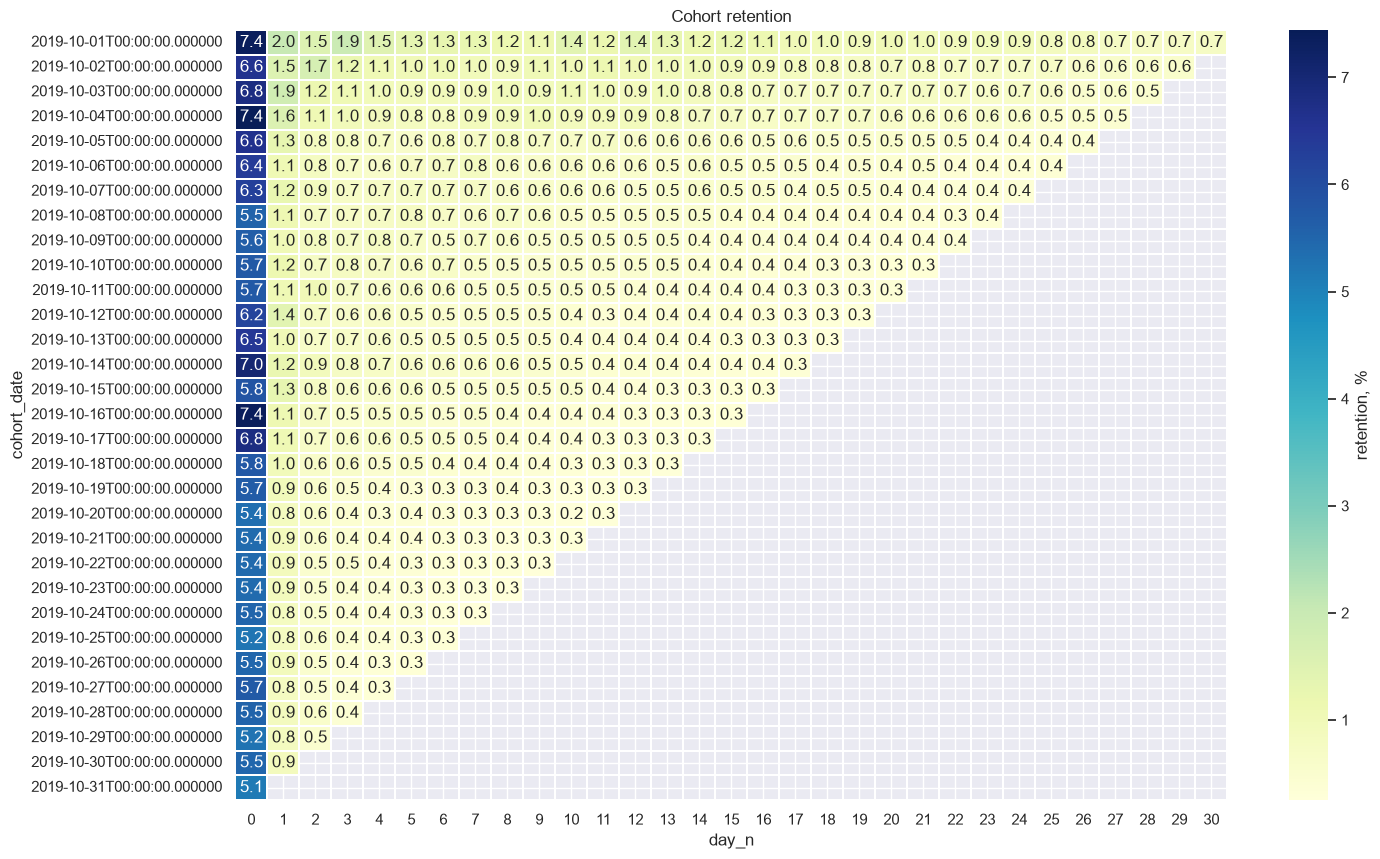

In [ ]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    pivot,
    annot=True, fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': 'retention, %'},
    linewidths=0.3,
)
plt.title('Cohort retention')
plt.xlabel('day_n')
plt.ylabel('cohort_date')
plt.savefig('img/heatmap.png')
plt.show()

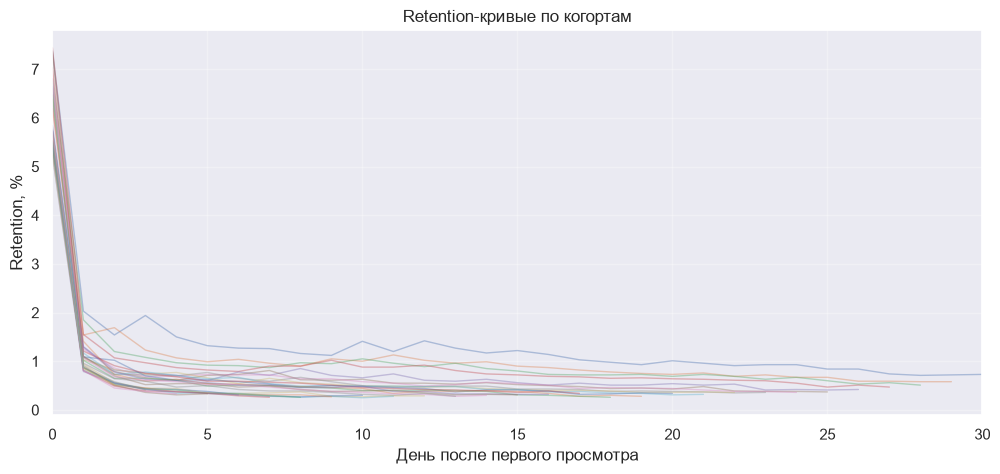

In [35]:
plt.figure(figsize=(12, 5))
for cdate, grp in df.groupby('cohort_date'):
    plt.plot(grp['day_n'], grp['retention_pct'], alpha=0.4, linewidth=1)
plt.xlim(0, 30)
plt.title('Retention-кривые по когортам')
plt.xlabel('День после первого просмотра')
plt.ylabel('Retention, %')
plt.grid(alpha=0.3)
plt.show()

### DAU, WAU, MAU, Sticky Factor

Ключевым событием возьмём то, когда пользователь положил товар в корзину.

DAU:

In [36]:
dau = con.sql('''
        SELECT COUNT(DISTINCT user_id) AS cnt, EXTRACT(DAY FROM event_time) AS day, EXTRACT(WEEK FROM event_time) AS week
        FROM events
        WHERE event_type = 'cart'
        GROUP BY EXTRACT(DAY FROM event_time), EXTRACT(WEEK FROM event_time)
        ORDER BY day
''').df()
dau.head(5)

,cnt,day,week
0,8771,1,40
1,8862,2,40
2,9793,3,40
3,21714,4,40
4,17457,5,40


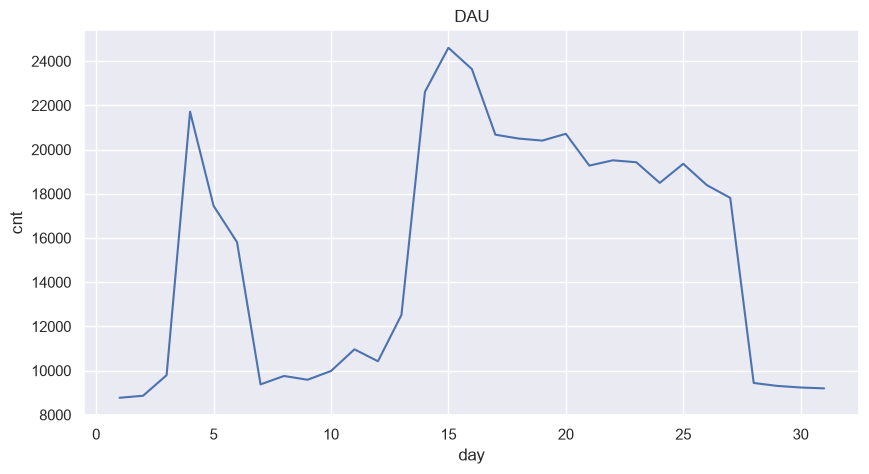

In [37]:
fig, ax = plt.subplots(figsize = (10, 5))
sns.lineplot(dau, x='day', y='cnt', ax = ax)
ax.set_title('DAU')
plt.show()

WAU:

In [38]:
wau = con.sql('''
        SELECT COUNT(DISTINCT user_id) AS cnt, EXTRACT(WEEK FROM event_time) AS week
        FROM events
        WHERE event_type = 'cart'
        GROUP BY EXTRACT(WEEK FROM event_time)
        ORDER BY week
''').df()

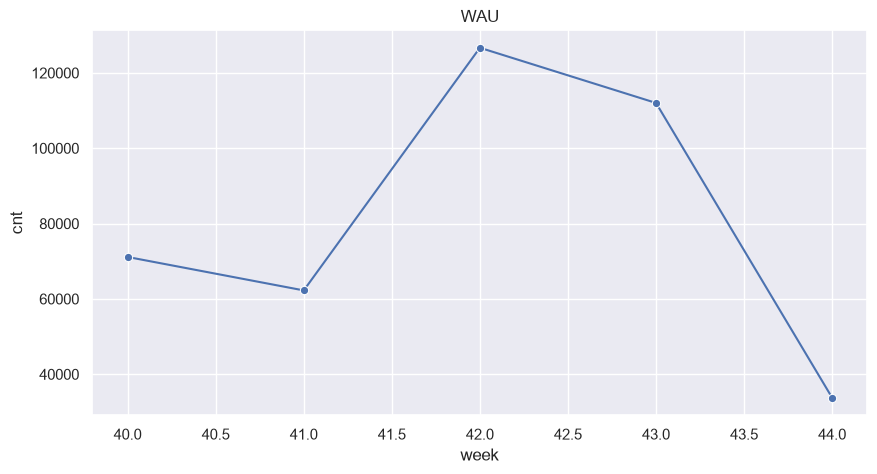

In [61]:
fig, ax = plt.subplots(figsize = (10,5))
sns.lineplot(wau, x='week', y='cnt', ax = ax, marker='o')
ax.set_title('WAU')
plt.show()

MAU, в нашем случае, это количество уникальных пользователей, которые добавили товар в корзину, так как мы имеем данные только на октябрь

In [40]:
mau = con.sql('''
        SELECT COUNT(DISTINCT user_id) AS cnt, EXTRACT(MONTH FROM event_time) AS month
        FROM events
        WHERE event_type = 'cart'
        GROUP BY EXTRACT(MONTH FROM event_time)
        ORDER BY month
''').df()

In [41]:
mau

,cnt,month
0,337117,10


Посчитаем Sticky Factor за месяц, то есть посмотрим какой процент от месячной аудитории заходит ежедневно и делает ключевое действие:

In [42]:
dau_day1 = dau.loc[dau['day'] == 1, 'cnt'].iloc[0]
mau_cnt  = mau['cnt'].iloc[0]

sticky = dau_day1 / mau_cnt * 100
print(f'{sticky:.2f} %')

2.60 %


Так как у нас информация только за один месяц, то больше информации мы сможем найти, если будет смотреть Sticky Factor за неделю.

Стоит учитывать, что у нас есть две неполные недели, которые будут давать некорректные данные.

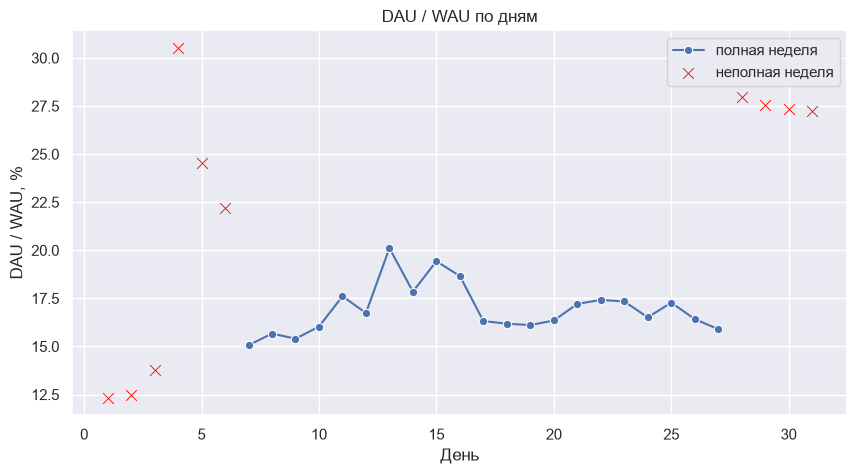

In [43]:
s_f_day_week = dau.merge(wau, how='left', on='week', suffixes=('_dau', '_wau'))
s_f_day_week['pct'] = (s_f_day_week['cnt_dau'] / s_f_day_week['cnt_wau'] * 100).round(2)

days_per_week = dau.groupby('week')['day'].nunique()
s_f_day_week['week_full'] = s_f_day_week['week'].map(days_per_week) == 7

s_f_day_week.drop(columns=['cnt_dau', 'cnt_wau'], inplace=True)

fig, ax = plt.subplots(figsize=(10, 5))

full = s_f_day_week[s_f_day_week['week_full']]
partial = s_f_day_week[~s_f_day_week['week_full']]

sns.lineplot(data=full, x='day', y='pct', marker='o', ax=ax, label='полная неделя')
sns.scatterplot(data=partial, x='day', y='pct', marker='x', s=60,
                color='red', ax=ax, label='неполная неделя')

ax.set_title('DAU / WAU по дням')
ax.set_xlabel('День')
ax.set_ylabel('DAU / WAU, %')
ax.legend()

plt.show()

### GMV, AOV

Посчитаем GMV и AOV на каждый день октября:

In [60]:
gmv_aov = con.sql('''
        SELECT ROUND(SUM(price), 2) AS GMV, EXTRACT(DAY FROM event_time) as day, 
                COUNT(DISTINCT user_session) AS cnt, ROUND(SUM(price), 2)/COUNT(DISTINCT user_session) AS AOV 
        FROM events
        WHERE event_type = 'purchase'
        GROUP BY EXTRACT(DAY FROM event_time) 
        ORDER BY day       
''').df()

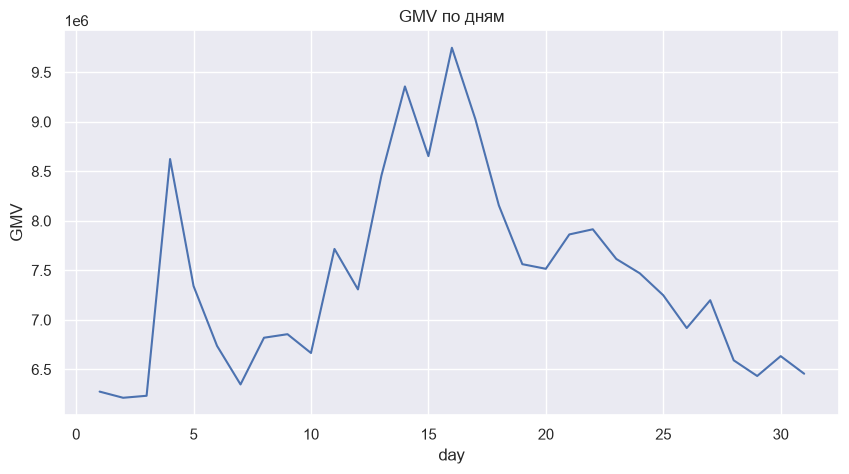

In [ ]:
fig, ax = plt.subplots(figsize = (10, 5))
sns.lineplot(gmv_aov, x='day', y='GMV', ax = ax)
ax.set_title('GMV по дням')
plt.savefig('img/gmv.png')
plt.show()

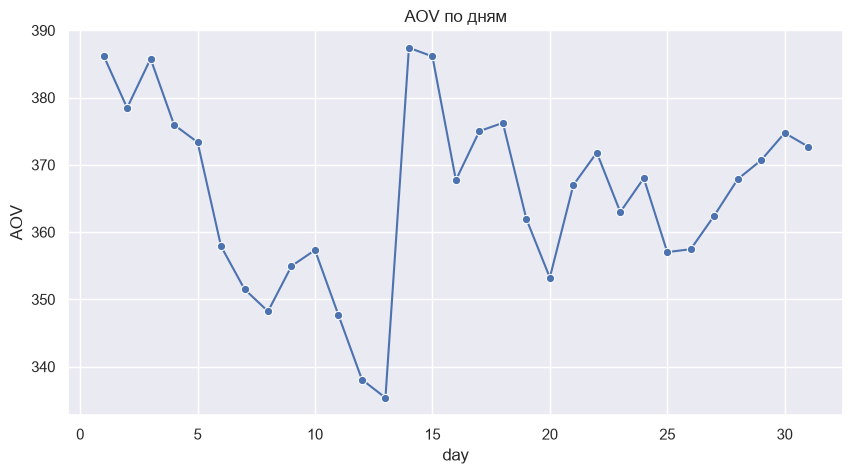

In [59]:
fig, ax = plt.subplots(figsize = (10, 5))
sns.lineplot(gmv_aov, x='day', y='AOV', ax = ax, marker='o')
ax.set_title('AOV по дням')
plt.show()

На всех графиках выше можно заметить то, что во второй неделе октября (или 42 неделя в году) наблюдается скачок многих параметров: AOV, GMV, WAU, DAU, количество продаж. Рассмотрим подробнее данную ситуацию. Будет смотреть окно с 13 по 20 октября.

Посмотрим какие товары пользовались наибольшим спросом в эту неделю:
- если заметим скачок по некоторым из них -> возможно на них была какая-то акция
- если не найдём -> посмотрим средние значения купленных товаров во всём месяце. Тут два варианта:
    - скидка была на все товары -> ценники будут занижены
    - какие-то праздники -> увеличенное количество покупок

Декомпозируем:

```latex
    GMV = orders * AOV 
    AOV = upt * avg_item_price 
```

Где orders - трафик, upt - сколько купили за сессию,  avg_item_price - средняя цена купленного. Будем смотреть каждый параметр и делать выводы.

Посмотрим динамику по неделям:

In [97]:
week_analys = con.sql('''
        SELECT EXTRACT(WEEK FROM event_time) AS week, 
            COUNT(DISTINCT user_session) AS orders,
            ROUND(SUM(price), 2) AS GMV,
            ROUND(SUM(price) / COUNT(DISTINCT user_session), 2) AS AOV,
            ROUND(COUNT(*) / COUNT(DISTINCT user_session), 2) AS upt,
            ROUND(AVG(price), 2) AS avg_item_price
        FROM events
        WHERE event_type = 'purchase' AND EXTRACT(WEEK FROM event_time) IN (41, 42, 43)
        GROUP BY week
        ORDER BY week
''').df()

week_analys

,week,orders,GMV,AOV,upt,avg_item_price
0,41,144619,50170639.94,346.92,1.18,294.52
1,42,160964,60017116.85,372.86,1.18,315.72
2,43,143491,52227725.82,363.98,1.18,308.55


Видно, что upt и avg_item_price сильно не изменились, а значит больше люди не стали покупать и дороже тоже не стали покупать.

In [104]:
gmv_w41 = week_analys.loc[week_analys['week'] == 41, 'GMV'].iloc[0]
gmv_w42 = week_analys.loc[week_analys['week'] == 42, 'GMV'].iloc[0]
gmv_w43 = week_analys.loc[week_analys['week'] == 43, 'GMV'].iloc[0]

aov_w41 = week_analys.loc[week_analys['week'] == 41, 'AOV'].iloc[0]
aov_w42 = week_analys.loc[week_analys['week'] == 42, 'AOV'].iloc[0]
aov_w43 = week_analys.loc[week_analys['week'] == 43, 'AOV'].iloc[0]

orders_w41 = week_analys.loc[week_analys['week'] == 41, 'orders'].iloc[0]
orders_w42 = week_analys.loc[week_analys['week'] == 42, 'orders'].iloc[0]
orders_w43 = week_analys.loc[week_analys['week'] == 43, 'orders'].iloc[0]


base_ord = (orders_w41 + orders_w43) / 2
lift_pct_ord = (orders_w42 - base_ord) / base_ord * 100

base_gmv = (gmv_w41 + gmv_w43) / 2
lift_pct_gmv = (gmv_w42 - base_gmv) / base_gmv * 100

base_aov = (aov_w41 + aov_w43) / 2
lift_pct_aov = (aov_w42 - base_aov) / base_aov * 100

week_analys2 = pd.DataFrame({'gmv_lift_pct': [round(lift_pct_gmv, 1)], 'orders_lift_pct': [round(lift_pct_ord, 1)], 'aov_lift_pct': [round(lift_pct_aov, 1)]})
week_analys2

,gmv_lift_pct,orders_lift_pct,aov_lift_pct
0,17.2,11.7,4.9


Получается больший вклад вносит повышение трафика людей.

Рассмотрим, для уверенности, подробнее информацию по брендам:

In [132]:
con.sql('''
        WITH weeks AS (
                SELECT
                    EXTRACT(WEEK FROM event_time) AS week,
                    category_code,
                    SUM(price) AS gmv
                FROM events
                WHERE event_type = 'purchase' AND EXTRACT(WEEK FROM event_time) IN (41, 42, 43) AND category_code IS NOT NULL
                GROUP BY week, category_code
                ),
        pivoted AS (
            SELECT
                category_code,
                MAX(CASE WHEN week = 41 THEN gmv END) AS w41,
                MAX(CASE WHEN week = 42 THEN gmv END) AS w42,
                MAX(CASE WHEN week = 43 THEN gmv END) AS w43
            FROM weeks
            GROUP BY category_code
        ),
        calc AS (
            SELECT
                category_code,
                w41, w42, w43,
                (w41 + w43) / 2 AS base,
                w42 - (w41 + w43) / 2 AS lift_abs
            FROM pivoted
        )
        SELECT
            category_code,
            ROUND(w41, 0) AS w41_gmv,
            ROUND(w42, 0) AS w42_gmv,
            ROUND(w43, 0) AS w43_gmv,
            ROUND((w42 - base) / NULLIF(base, 0) * 100, 1) AS lift_pct,
            ROUND(lift_abs, 0) AS lift_abs,
            ROUND(100.0 * lift_abs / SUM(lift_abs) OVER (), 1) AS lift_abs_pct
        FROM calc
        ORDER BY lift_abs DESC
        LIMIT 20;
''').show()

┌───────────────────────────────────┬────────────┬────────────┬────────────┬──────────┬───────────┬──────────────┐
│           category_code           │  w41_gmv   │  w42_gmv   │  w43_gmv   │ lift_pct │ lift_abs  │ lift_abs_pct │
│              varchar              │   double   │   double   │   double   │  double  │  double   │    double    │
├───────────────────────────────────┼────────────┼────────────┼────────────┼──────────┼───────────┼──────────────┤
│ electronics.smartphone            │ 33493402.0 │ 41373445.0 │ 35583367.0 │     19.8 │ 6835061.0 │         78.6 │
│ computers.notebook                │  1857826.0 │  2407287.0 │  1996451.0 │     24.9 │  480148.0 │          5.5 │
│ electronics.video.tv              │  1656924.0 │  2291973.0 │  2055391.0 │     23.5 │  435815.0 │          5.0 │
│ appliances.kitchen.washer         │   885841.0 │  1303824.0 │  1183620.0 │     26.0 │  269094.0 │          3.1 │
│ electronics.clocks                │  1013057.0 │  1293748.0 │  1104435.0 │    

In [124]:
con.sql('''
        SELECT COUNT(*) FILTER (WHERE category_code LIKE 'electronics.smartphone') AS cnt_smart,
        COUNT(*) AS total_cnt_smart,
        ROUND(COUNT(*) FILTER (WHERE category_code LIKE 'electronics.smartphone') / COUNT(*)*100, 2) AS pct_smart
        FROM events        
        WHERE event_type = 'purchase'
''').show()

┌───────────┬─────────────────┬───────────┐
│ cnt_smart │ total_cnt_smart │ pct_smart │
│   int64   │      int64      │  double   │
├───────────┼─────────────────┼───────────┤
│    338018 │          742849 │      45.5 │
└───────────┴─────────────────┴───────────┘



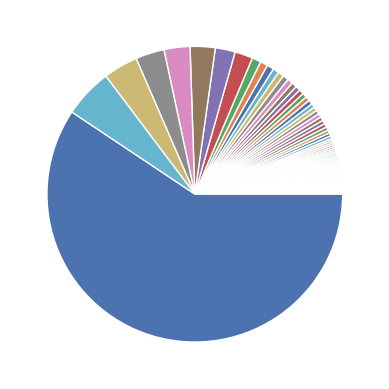

In [126]:
cnt_cat = con.sql('''
        SELECT category_code, COUNT(*) AS cnt
        FROM events
        WHERE category_code IS NOT NULL AND event_type = 'purchase'
        GROUP BY category_code 
        ORDER BY cnt       
''').df()

plt.pie(cnt_cat['cnt'])
plt.show()

На 42-й неделе октября произошёл общий подъём активности на маркетплейсе: все категории выросли на 10–30%, у части нишевых товаров наблюдался рост до 95%. Смартфоны, занимая большую асть GMV, дали 78% абсолютного прироста — это эффект масштаба, а не таргетированной кампании. Рост GMV на ~70% обусловлен объёмом заказов и на ~30% — ростом средней цены позиции

# Вывод

В октябре 2019 маркетплейс показал $230M GMV, 6,2% view→cart и 50,7% cart→purchase по сессиям. Retention низкий в D1 (2%), но окно возврата широкое (windowed D30 = 20%). Всплеск середины месяца (+17,2% GMV) — трафиковый, а не промо-ценовой, с доминирующим вкладом смартфонов (78,6% прироста, но за счёт масштаба). Главные точки роста — воронка (view→cart, cart→purchase).

Не забываем закрывать соединение с duckdb

In [ ]:
con.close()